In [1]:
from sympy import *
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
import time

# %matplotlib notebook
%matplotlib inline

init_printing(use_latex=True)

DIVu 0
2.0*pi**2*thick*sin(2*pi*x) - 2*pi*x*(1.0 - x) 

 -2*pi*cos(2*pi*x) + 2*pi

 ----------------
 Rod solution
 ----------------

 ud= 2.0*pi**2*thick*sin(2*pi*x) - 2*pi*x*(1.0 - x) 

 vd=  -2*pi*cos(2*pi*x) + 2*pi 


 u= t**4*(2.0*pi**2*thick*sin(2*pi*x) - 2*pi*x*(1.0 - x)) 

 v=  t**4*(-2*pi*cos(2*pi*x) + 2*pi) 


 up=  t**4*(4.0*pi**3*thick*cos(2*pi*x) + 2*pi*x - 2*pi*(1.0 - x)) 

 vp=  4*pi**2*t**4*sin(2*pi*x) 


 upp=  t**4*(-8.0*pi**4*thick*sin(2*pi*x) + 4*pi) 

 vpp=  8*pi**3*t**4*cos(2*pi*x) 


 fu=  -Ce*t**4*(-8.0*pi**4*thick*sin(2*pi*x) + 4*pi) - 4.0*pi**2*mu*t**3*sin(2*pi*x) 

 fv=  -32*pi**5*Ck*t**4*cos(2*pi*x) - mu*t**3*(-4.0*pi*x + 4.0*pi*(1.0 - x)) + 1.0*t**2*cos(pi*x)

 ----------------
 Fluid solution
 ----------------

 ufl=  -2*pi*x*(1.0 - x)*cos(2*pi*y) 

 vfl=  -x*sin(2*pi*y) + (1.0 - x)*sin(2*pi*y) - 2*pi*cos(2*pi*x) + 2*pi 

 p=  t**2*cos(pi*x)*cos(pi*y) 


 flforceu=  -mu*t**3*(8*pi**3*x*(1.0 - x)*cos(2*pi*y) + 4*pi*cos(2*pi*y)) - pi*t**2*sin(pi*x)*cos(pi*y)

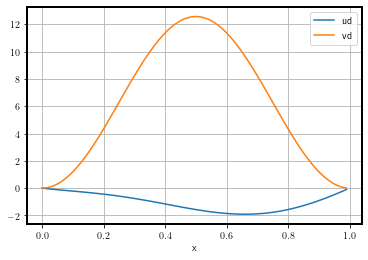

In [16]:
verbose = True

# Symbols
x, y, t = symbols('x y t')

# Domain size
L = 1.0
H = 1.0

sx = -pi*sin(pi*x)*cos(pi*y)
sy = -pi*cos(pi*x)*sin(pi*y)

mu = 1.0
mu = symbol('mu')
beta = 10.0
beta = symbol('beta')
kappa = 1.0
kappa = symbol('kappa')
gx = -(mu/kappa)*sx + beta*sqrt(sx**2 + sy**2)*sx
gy = -(mu/kappa)*sy + beta*sqrt(sx**2 + sy**2)*sy

p = integrate(gx, x)
p = integrate(gx, x)

source = diff(sx,x) + diff(sy,y)

'''
print('Mean pressure', integrate(p.subs({t:1, y:0}), (x, 0, L)))
#print(ud.subs({x:0.5*L, y:0.5*H, t:0.5}))
#print(ud.subs({x:L, t:0.25}))
#display('ufl=', ufl)
#display('vfl=', vfl)
#display(divu)
#display(ud)
#print(vd.subs({x:0}))

tx = np.arange(0.0, 1.0, 0.01)
sx = lambdify([x],sx.subs({thick:0.03, t:1e-10}))
sy = lambdify([x],sy.subs({t:1e-10}))

Ud = sud(tx)
Vd = svd(tx)
#pr = spd(tx)

fig, ax = plt.subplots()
ax.plot(tx,Ud)
ax.plot(tx,Vd)
#ax.plot(tx,pr)
#help(ax)
ax.set(xlabel='x', ylabel='', title='')
ax.legend(['ud', 'vd'])
ax.grid()
plt.show()
'''


-2*pi*x*(1.0 - x)*cos(2*pi*y)


NameError: name 'cp' is not defined

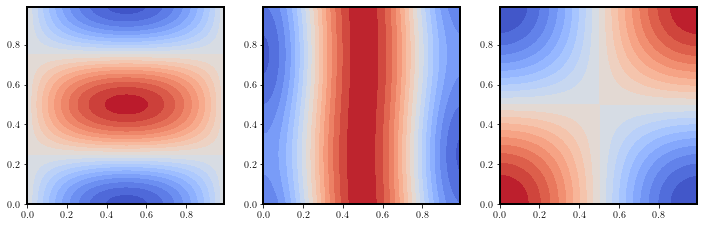

In [17]:
print(ufl)
nufl = lambdify([x,y],ufl.subs({t:1}))
nvfl = lambdify([x,y],vfl.subs({t:1}))
newp = lambdify([x,y],p.subs({t:1}))

xa = np.arange(0,L,L/100)
ya = np.arange(0,H,H/100)
X,Y=np.meshgrid(xa,ya)
Zu = nufl(X,Y)
Zv = nvfl(X,Y) 
P = newp(X,Y)

fig, (ax1, ax2, ax3) = plt.subplots(1,3)
fig.set_figwidth(12)
fig.set_figheight(12)

#help(ax1.contourf)
ax1.contourf(X, Y, Zu, 20, cmap='coolwarm')
ax2.contourf(X, Y, Zv, 20, cmap='coolwarm')
ax3.contourf(X, Y, P, 20, cmap='coolwarm')
ax1.set_aspect('equal', 'box')
ax2.set_aspect('equal', 'box')
ax3.set_aspect('equal', 'box')

#cp = plt.contourf(X, Y, Zv, cmap='RdBu')
cb = plt.colorbar(cp, cmap='RdBu')
cp = plt.contourf(X, Y, P, cmap='RdBu')

plt.show()